<div>
    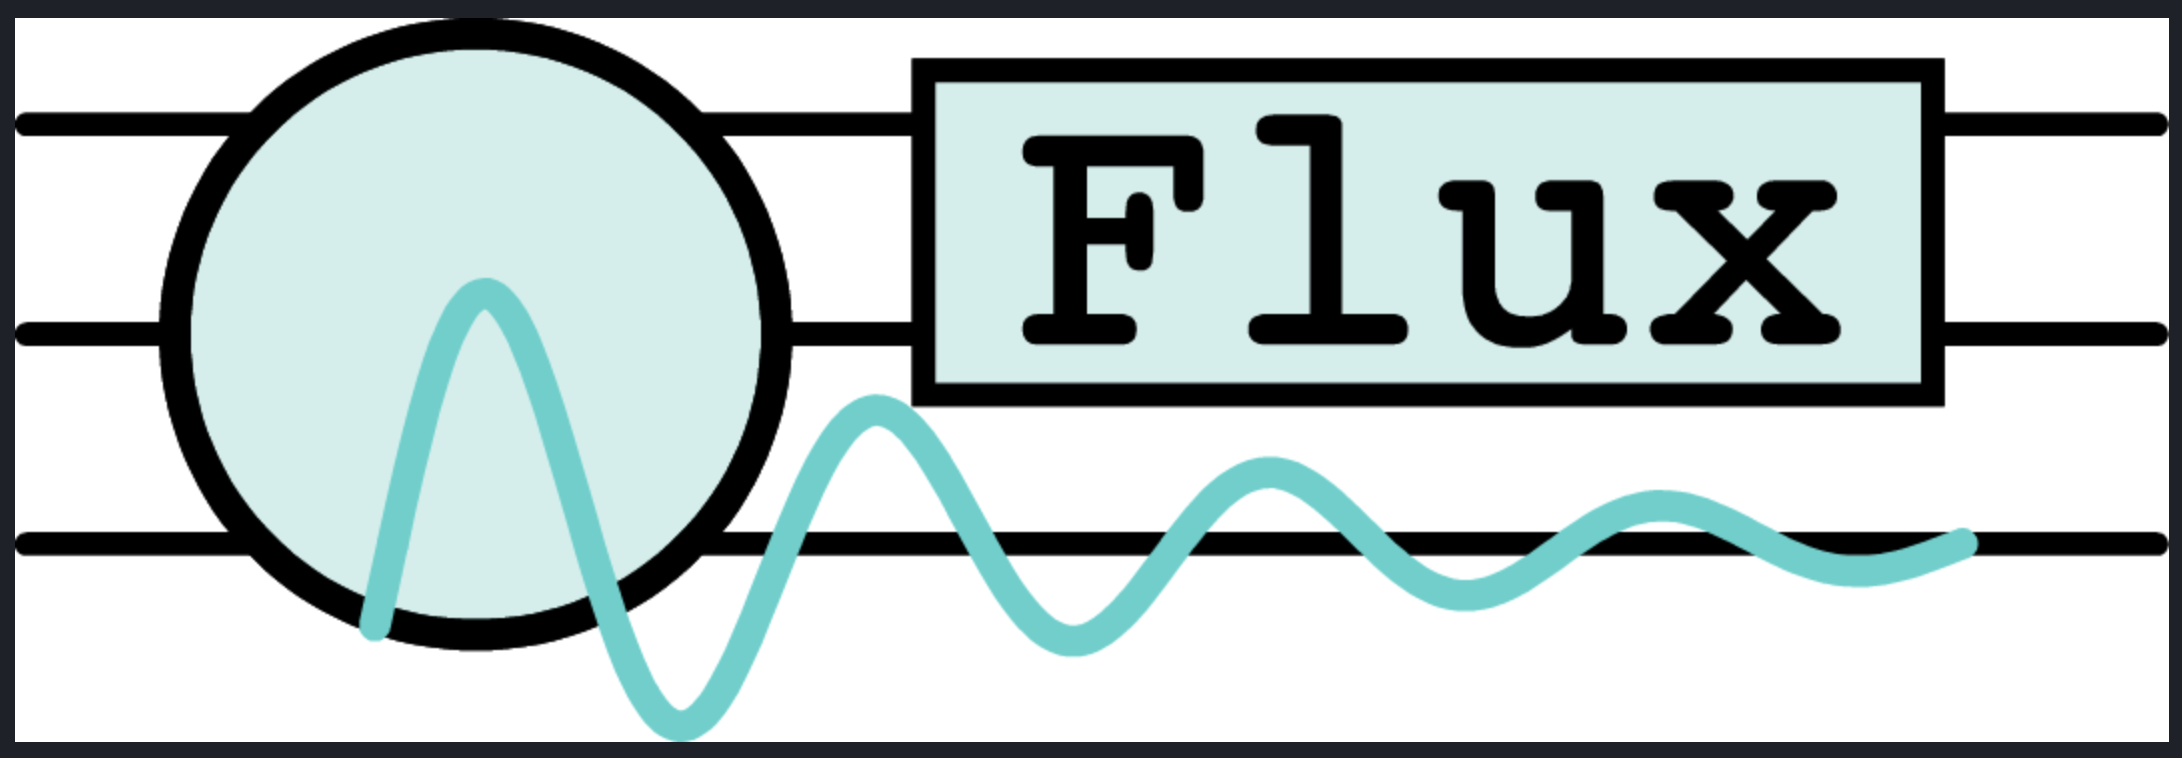
</div>


# Package Installations

- `qiskit` for circuit construction,
- `qiskit-aer` for noisy density-matrix simulation,
- `numpy` and `matplotlib` for numerical analysis and plots.

In [1]:
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    print("We are in Google Colab: installing apbs-binary, pymol-open-source, numpy, pandas")
    !pip install -q qiskit qiskit-aer qiskit-ibm-runtime matplotlib numpy scipy pylatexenc pandas tqdm
else:
    print("We are not in Google Colab: all the packages are asumed to be installed in the current environment")

from importlib.metadata import version

for pkg in ["numpy", "scipy", "pylatexenc", "pandas", "qiskit", "qiskit-aer", "qiskit-ibm-runtime", "matplotlib", "tqdm"]:
    print(f"{pkg}: {version(pkg)}")

We are not in Google Colab: all the packages are asumed to be installed in the current environment
numpy: 2.5.2
scipy: 1.18.0
pylatexenc: 2.11
pandas: 3.0.5
qiskit: 2.5.2
qiskit-aer: 0.17.2
qiskit-ibm-runtime: 0.49.0
matplotlib: 3.11.1
tqdm: 4.70.0


In [2]:
from __future__ import annotations

import itertools
import math

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

import tqdm

np.set_printoptions(precision=6, suppress=True)

# **QFlux Tutorial**

<h2> This notebook implements codes referenced in the Supporting Information for: </h2>

<h2>
<b> QFlux: Quantum Circuit Implementations for Molecular Dynamics </b>
</h2>

<h2> <b>Part VII: Quantum Error Correction and Mitigation</b> </h2>

<h3>
    <b>Authors:</b> <br><br>
Brandon C. Allen, Chuzhi Xu, Brian Gitahi, Francesco Calcagno, Yue Yu, Alexander V. Soudackov, Ivan Rivalta, and Victor S. Batista
</h3>

**Note:** Each section builds on the previous ones. **Execute the cells sequentially**, as later sections might rely on functions and data defined earlier.

# Table of Contents

* Section 6.3.1: Depolarizing noise model

  - <a href="#PECcore">Shared PEC helpers (quasi-probability decomposition, noise model)</a>

* Section 6.3.2: Single-qubit $R_y(\theta)$ gate

  - <a href="#ScriptS6pt1">Script S.6.1: Minimal PEC implementation in Qiskit Aer for the $R_y$ gate</a>

* Section 6.3.3: Two-qubit CNOT gate

  - <a href="#ScriptS6pt2">Script S.6.2: Minimal PEC implementation in Qiskit Aer for the CNOT gate</a>

# Helper Functions

In [3]:
def build_ry_circuit(theta: float) -> QuantumCircuit:
    """Return a one-qubit circuit containing a single Ry(theta) gate."""
    circuit = QuantumCircuit(1)
    circuit.ry(theta, 0)
    return circuit

def build_cnot_circuit() -> QuantumCircuit:
    """Prepare |10> in Qiskit's little-endian convention, then apply CX(0, 1)."""
    circuit = QuantumCircuit(2)
    circuit.x(0)
    circuit.cx(0, 1)
    return circuit

# Section 6. Probabilistic Error Cancellation

For an ideal operation $\mathcal{U}$ and its noisy implementation
$$
\widetilde{\mathcal{U}} = \mathcal{D} \circ \mathcal{U},
$$

PEC seeks a representation
$$
\mathcal{U} = \sum_n \alpha_n \mathcal{B}_n,\quad \alpha_n\in\mathbb{R}
$$
where the $\mathcal{B}_n$ are implementable operations and the coefficients $\alpha_n$ may be negative. Define
$$
\gamma = \sum_n |\alpha_n|, \qquad q_n = \frac{|\alpha_n|}{\gamma}, \qquad s_n = \operatorname{sign}(\alpha_n).
$$

Sampling $n \sim q_n$ gives the unbiased estimator
$$
{\langle\hat{O}\rangle}_{\mathrm{PEC}}
= \frac{\gamma}{N}\sum_{n=1}^N s_n {\langle\hat{O}\rangle}_{n}.
$$

The estimator is unbiased when the representation noise model matches the actual noise. The cost is variance: the shot budget scales roughly like $\gamma^2$.

## PEC Workflow

1. `pec_decomposition_depolarizing(p, n_qubits)` returns the Pauli labels, the quasi-probability coefficients $\alpha_n$ of the inverse depolarizing channel, the one-norm $\gamma$, the sampling probabilities $q_n$ and the signs $s_n$.
2. `pec_estimate_ry` (Script S.6.1) and `pec_estimate_cnot` (Script S.6.2) run the Monte Carlo loop: sample a Pauli correction $n\sim q_n$, append it after the noisy gate, measure, and accumulate $\gamma\, s_n \langle\hat O\rangle_n$.

$$
\text{ideal circuit}
\longrightarrow
\text{quasi-probability coefficients}
\longrightarrow
\text{sampled Pauli corrections}
\longrightarrow
\text{signed estimator}.
$$

## 6.3. $R_y$ and CNOT gates under depolarizing noise

We derive the PEC decomposition explicitly for two textbook gates, a single-qubit rotation $R_y(\theta)=\exp(-i\theta Y/2)$ and the two-qubit CNOT, assuming each gate is followed by an isotropic depolarizing channel.

### 6.3.1. Depolarizing noise model

For a general $n$-qubit operation, the symmetric Pauli depolarizing channel with total error rate $p$ is

$$
\mathcal{D}_p^{(n)}(\rho) = (1-p)\,\rho + \frac{p}{4^{n}-1}\sum_{P\neq I^{\otimes n}} P\rho P^{\dagger},
$$

which contracts every non-identity Pauli component by $f_n = 1 - \dfrac{4^n p}{4^n-1}$. Its inverse has the quasi-probability decomposition

$$
\alpha_{I} = \frac{4^n + f_n - 1}{4^n f_n}, \qquad
\alpha_{P\neq I} = \frac{f_n - 1}{4^n f_n}, \qquad
\gamma_n = \sum_P |\alpha_P|,
$$

so that $\gamma_1 = \dfrac{1+2p/3}{1-4p/3}$ and $\gamma_2 = \dfrac{1+14p/15}{1-16p/15}$.

**Convention note.** Qiskit's `depolarizing_error(lam, n)` is defined as $(1-\lambda)\rho + \lambda\, I/2^n$, which equals $\mathcal{D}^{(n)}_p$ only for $\lambda = \dfrac{4^n}{4^n-1}\,p$. `build_noise_model` therefore passes $4p_1/3$ and $16p_2/15$ to Qiskit, so that the simulated noise is exactly the channel inverted by `pec_decomposition_depolarizing`. Without this rescaling the estimator over-corrects by a factor $(1-\lambda)/f_n$ (e.g. $\langle Z\rangle \to 0.509$ instead of $0.5$ at $p_1=0.05$).

The helpers below are shared by Scripts S.6.1 and S.6.2. The noise model attaches depolarizing errors **only** to `ry` (one-qubit) and `cx` (two-qubit) gates, so the inserted Pauli corrections and the clean Hadamard in the Bell-state circuit are noiseless.
<a name="PECcore"></a>

In [4]:
def pec_decomposition_depolarizing(p, n_qubits):
    """
    Closed-form quasi-probability decomposition of D_p^{-1}
    for an n-qubit Pauli-depolarizing channel of total rate p.
    """
    dim = 4 ** n_qubits
    f = 1.0 - dim * p / (dim - 1)
    alpha_I = (dim + f - 1.0) / (dim * f)
    alpha_P = (f - 1.0) / (dim * f)
    labels = [''.join(t) for t in
              itertools.product('IXYZ', repeat=n_qubits)]
    alphas = np.array([alpha_I if lbl == 'I' * n_qubits else alpha_P
                       for lbl in labels])
    gamma = float(np.sum(np.abs(alphas)))
    return labels, alphas, gamma, np.abs(alphas)/gamma, np.sign(alphas).astype(int)

def build_noise_model(p1=0.0, p2=0.0):
    nm = NoiseModel()
    if p1 > 0:
        # Qiskit's depolarizing_error(lam, n) is (1-lam)*rho + lam*I/2^n, i.e. a total
        # Pauli error rate lam*(4^n-1)/4^n. Rescale so the channel matches D_p^(n) with
        # total error rate p, as assumed by pec_decomposition_depolarizing.
        nm.add_all_qubit_quantum_error(depolarizing_error(4 * p1 / 3, 1), ['ry'])
    if p2 > 0:
        nm.add_all_qubit_quantum_error(depolarizing_error(16 * p2 / 15, 2), ['cx'])
    return nm

def _append_pauli(qc, label, qubits):
    for ch, q in zip(label, qubits):
        if ch == 'X': qc.x(q)
        elif ch == 'Y': qc.y(q)
        elif ch == 'Z': qc.z(q)

Cross-check the numerical decomposition against the closed-form one-norms $\gamma_1$, $\gamma_2$, and reproduce the table of quasi-probability coefficients and sampling overheads $\gamma^2$ quoted in the main text.

In [5]:
def gamma_1q_depolarizing(p):
    """Closed-form one-norm for one noisy one-qubit gate."""
    return (1 + 2 * p / 3) / (1 - 4 * p / 3)

def gamma_2q_depolarizing(p):
    """Closed-form one-norm for one noisy two-qubit gate."""
    return (1 + 14 * p / 15) / (1 - 16 * p / 15)

def pec_num_samples(n_noisy: int, gamma: float, n_per_sample: int=1) -> int:
    """Number of PEC samples M so the total PEC budget ≈ gamma^2 * N_noisy shots."""
    if n_per_sample < 1 or n_noisy < 1 or gamma < 1:
        raise ValueError("Require n_per_sample >= 1, n_noisy >= 1, gamma >= 1.")
    n_total = gamma**2 * n_noisy               # total PEC shots for equal precision
    return math.ceil(n_total / n_per_sample)   # number of samples, each run with s shots

print(f"{'Gate':>6} {'p':>6} {'alpha_I':>9} {'alpha_P':>12} {'gamma':>8} {'gamma^2':>8}")
for gate, n, gamma_closed in [("Ry", 1, gamma_1q_depolarizing), ("CNOT", 2, gamma_2q_depolarizing)]:
    for p in [0.01, 0.05]:
        labels, alphas, gamma, _, _ = pec_decomposition_depolarizing(p, n)
        assert np.isclose(gamma, gamma_closed(p)), (gate, p)
        print(f"{gate:>6} {p:6.2f} {alphas[0]:9.4f} {alphas[1]:12.3e} {gamma:8.4f} {gamma**2:8.4f}")

  Gate      p   alpha_I      alpha_P    gamma  gamma^2
    Ry   0.01    1.0101   -3.378e-03   1.0203   1.0410
    Ry   0.05    1.0536   -1.786e-02   1.1071   1.2258
  CNOT   0.01    1.0101   -6.739e-04   1.0202   1.0408
  CNOT   0.05    1.0528   -3.521e-03   1.1056   1.2224


### 6.3.2. Single-qubit $R_y(\theta)$ gate

The rotation gate is

$$
R_y(\theta) = e^{-i\theta Y/2}
= \begin{pmatrix}
\cos(\theta/2) & -\sin(\theta/2) \\
\sin(\theta/2) & \cos(\theta/2)
\end{pmatrix}.
$$

Starting from $|0\rangle$,

$$
R_y(\theta)|0\rangle
= \cos\left(\frac{\theta}{2}\right)|0\rangle
+ \sin\left(\frac{\theta}{2}\right)|1\rangle,
$$

so $\langle Z\rangle_{\mathrm{ideal}}=\cos\theta$.

Setting $n=1$ gives $f_1 = 1-4p/3$,

$$
\alpha_I = \frac{1-p/3}{1-4p/3}, \qquad
\alpha_X=\alpha_Y=\alpha_Z=\alpha = -\frac{p/3}{1-4p/3}, \qquad
\gamma_1 = \frac{1+2p/3}{1-4p/3},
$$

and the $R_y$ superoperator decomposes as

$$
R_y(\theta) = \alpha_I\,\widetilde{R}_y(\theta) + \alpha\left[\mathcal{X}\circ\widetilde{R}_y(\theta) + \mathcal{Y}\circ\widetilde{R}_y(\theta) + \mathcal{Z}\circ\widetilde{R}_y(\theta)\right],
$$

where $\widetilde{R}_y(\theta)$ is the noisy gate and the Pauli channels are inserted after it. Script S.6.1 implements this estimator for $\langle Z\rangle$.
<a name="ScriptS6pt1"></a>

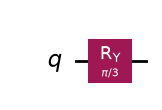

In [6]:
theta = math.pi / 3
ry_circuit = build_ry_circuit(theta)
ry_circuit.draw("mpl")

#### Script S.6.1: Minimal PEC implementation in Qiskit Aer for the $R_y$ gate

In [7]:
from tqdm import tqdm

def pec_estimate_ry(theta: float, p1: float, num_samples: int = 4096, num_shots_per_sample: int=1, seed: int | None = None, quiet: bool = False) -> float:
    labels, _, Q, probs, signs = pec_decomposition_depolarizing(p1, 1)
    rng = np.random.default_rng(seed)
    sim = AerSimulator(noise_model=build_noise_model(p1=p1))
    acc = 0.0
    acc2 = 0.0
    for _ in tqdm(range(num_samples), colour="green", desc="Sampling Pauli corrections (PEC)", disable=quiet):
        i = int(rng.choice(len(labels), p=probs))
        qc = QuantumCircuit(1, 1)
        qc.ry(theta, 0)
        _append_pauli(qc, labels[i], [0])
        qc.measure(0, 0)
        counts = sim.run(transpile(qc, sim), shots=num_shots_per_sample).result().get_counts()
        z = (counts.get('0', 0) - counts.get('1', 0))/num_shots_per_sample
        acc += int(signs[i]) * z
        acc2 += z**2
    acc2_avg = acc2/num_samples
    pec_estimate = Q*acc/num_samples
    pec_std = np.sqrt(
               (Q**2*(acc2_avg + (1-acc2_avg)/num_shots_per_sample)) / num_samples
               )
    return pec_estimate, pec_std       # unbiased estimator of <Z>

Unmitigated reference: the same noisy $R_y(\theta)$ circuit measured directly, without Pauli insertions.

In [8]:
def noisy_ry_z(theta, p1, shots=4096, seed=None):
    sim = AerSimulator(noise_model=build_noise_model(p1=p1))
    qc = QuantumCircuit(1, 1)
    qc.ry(theta, 0)
    qc.measure(0, 0)
    counts = sim.run(transpile(qc, sim), shots=shots, seed_simulator=seed).result().get_counts()
    s = sum(counts.values())
    return (counts.get('0', 0) - counts.get('1', 0)) / s

#### Typical single run for $R_y$ gate

$\theta=\pi/3$, $p_1=0.05$, $N_s=4096$ samples; the ideal value is $\langle Z\rangle = \cos(\pi/3) = 0.5$.

In [9]:
# Example: noisy RY(pi/3) with depolarizing noise level p = 0.05

theta = np.pi / 3
z_ideal = np.cos(theta)
p1 = 0.05
Ns_noisy = 2048

_, _, gamma1, _, _ = pec_decomposition_depolarizing(p1, 1)

Ns_per_sample = 1
Ns_pec = pec_num_samples(Ns_noisy, gamma1, n_per_sample=Ns_per_sample)

print()
print(f"Depolarizing noise level p1 = {p1}")
print(f"gamma_1^2    = {gamma1**2:.4f}")
print(f"Number of noisy shots = {Ns_noisy}")
print(f"Number of PEC samples = {Ns_pec}")
print(f"Number of shots per PEC sample = {Ns_per_sample}")
print()

z_pec, z_pec_std = pec_estimate_ry(theta, p1, num_samples=Ns_pec, num_shots_per_sample=Ns_per_sample, seed=11)
z_pec_std_check = np.sqrt((gamma1**2 - z_ideal**2) / Ns_pec)

z_noisy = noisy_ry_z(theta, p1, shots=Ns_noisy, seed=7)
z_noisy_std = np.sqrt((1 - z_noisy**2) / Ns_noisy)

print()
print(f"ideal <Z>    = {z_ideal:.4f}")
print(f"noisy <Z>    = {z_noisy:.4f} ± {z_noisy_std:.4f} ({Ns_noisy} shots)")
print(f"PEC   <Z>_em = {z_pec:.4f} ± {z_pec_std:.4f} ({Ns_pec} samples with {Ns_per_sample} shot(s) each)")

print(f"[z_pec_std_check = {z_pec_std_check:.4f}]")



Depolarizing noise level p1 = 0.05
gamma_1^2    = 1.2258
Number of noisy shots = 2048
Number of PEC samples = 2511
Number of shots per PEC sample = 1



Sampling Pauli corrections (PEC): 100%|██████████| 2511/2511 [00:37<00:00, 66.28it/s]


ideal <Z>    = 0.5000
noisy <Z>    = 0.4668 ± 0.0195 (2048 shots)
PEC   <Z>_em = 0.4916 ± 0.0221 (2511 samples with 1 shot(s) each)
[z_pec_std_check = 0.0197]


#### $R_y$ results table

Mean $\pm$ standard deviation over multiple runs with $N_s=4096$, at the two error rates of the coefficient table above.

In [12]:
theta = math.pi / 3
ideal_z = math.cos(theta)
n_reps = 16
Ns_noisy = 2048
Ns_per_sample = 1
seeds = list(range(n_reps))

ry_rows = []
for p1 in tqdm([0.01, 0.02, 0.05, 0.1], desc="Loop over noise levels", colour="magenta"):
    _, _, gamma1, _, _ = pec_decomposition_depolarizing(p1, 1)
    Ns_pec = pec_num_samples(Ns_noisy, gamma1, n_per_sample=Ns_per_sample)
    pec_vals = [pec_estimate_ry(theta, p1, num_samples=Ns_pec, num_shots_per_sample=Ns_per_sample, seed=s, quiet=True)[0] for s in seeds]
    noisy_vals = [noisy_ry_z(theta, p1, shots=Ns_noisy, seed=100 + s) for s in seeds]
    ry_rows.append(dict(
        p1=p1, ideal=ideal_z,
        noisy_mean=float(np.mean(noisy_vals)), noisy_std=float(np.std(noisy_vals)),
        pec_mean=float(np.mean(pec_vals)), pec_std=float(np.std(pec_vals)),
        gamma1=gamma1, gamma1_sq=gamma1**2,
    ))

from IPython.display import Markdown, display

header = (
    r"| $p_1$ | ideal $\langle Z\rangle$ | noisy $\langle Z\rangle$ "
    r"| PEC $\langle Z\rangle_{\mathrm{em}}$ | $\gamma_1^2$ |"
)
sep = "|---:|---:|---:|---:|---:|"
body = [
    f"| {r['p1']:.2f} | {r['ideal']:.4f} | "
    f"{r['noisy_mean']:.4f} ± {r['noisy_std']:.4f} | "
    f"{r['pec_mean']:.4f} ± {r['pec_std']:.4f} | "
    f"{r['gamma1_sq']:.4f} |"
    for r in ry_rows
]
display(Markdown("\n".join([header, sep, *body])))

| $p_1$ | ideal $\langle Z\rangle$ | noisy $\langle Z\rangle$ | PEC $\langle Z\rangle_{\mathrm{em}}$ | $\gamma_1^2$ |
|---:|---:|---:|---:|---:|
| 0.01 | 0.5000 | 0.4948 ± 0.0257 | 0.4984 ± 0.0185 | 1.0410 |
| 0.02 | 0.5000 | 0.4864 ± 0.0252 | 0.5016 ± 0.0156 | 1.0839 |
| 0.05 | 0.5000 | 0.4672 ± 0.0247 | 0.5057 ± 0.0183 | 1.2258 |
| 0.10 | 0.5000 | 0.4346 ± 0.0241 | 0.5029 ± 0.0207 | 1.5148 |

#### $R_y$ PEC convergence

PEC is unbiased only in the infinite-sample limit. Repeat the estimate for several values of $N_s$ at $p_1 = 0.05$ and compare with the ideal and noisy values.

Loop over numbers of shots: 100%|██████████| 7/7 [49:01<00:00, 420.16s/it]


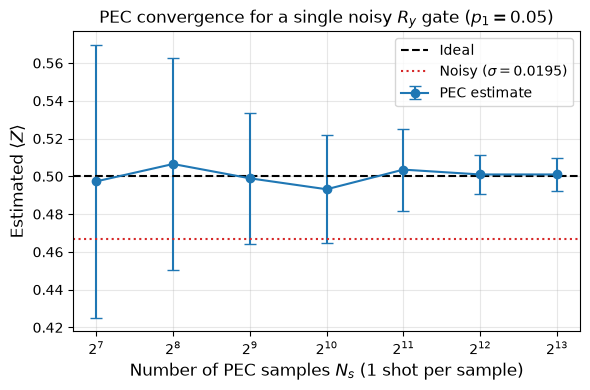

In [ ]:
n_qubits = 1
p1_conv = 0.05
Ns_noisy = 2048
shots_grid = [2**7, 2**8, 2**9, 2**10, 2**11, 2**12, 2**13]
replicates = 16

ry_mean, ry_std, ry_noisy_mean, ry_noisy_std = [], [], [], []
for n_shots in tqdm(shots_grid, desc="Loop over numbers of shots", colour="green"):
    _, _, gamma1, _, _ = pec_decomposition_depolarizing(p1, n_qubits)
    Ns_pec = n_shots
    reps = [pec_estimate_ry(theta, p1_conv, num_samples=Ns_pec, seed=1000+37*rep+n_shots, quiet=True)[0] for rep in range(replicates)]
    ry_mean.append(float(np.mean(reps)))
    ry_std.append(float(np.std(reps)))

noisy_z = (1 - 4 * p1_conv / 3)*math.cos(theta)
noisy_z_std = np.sqrt((1 - noisy_z**2)/Ns_noisy)

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(shots_grid, ry_mean, yerr=ry_std, marker="o", capsize=4, label="PEC estimate")
ax.axhline(math.cos(theta), color="black", linestyle="--", label="Ideal")
ax.axhline(noisy_z, color="tab:red", linestyle=":", label=fr"Noisy ($\sigma = {noisy_z_std:.4f}$)")
ax.set_xscale("log", base=2)
ax.set_xlabel(r"Number of PEC samples $N_s$ (1 shot per sample)", fontsize=12)
ax.set_ylabel(r"Estimated $\langle Z \rangle$", fontsize=12)
ax.set_title(fr"PEC convergence for a single noisy $R_y$ gate ($p_1={p1_conv}$)", fontsize=12)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

### 6.3.3. Two-qubit CNOT gate

Setting $n=2$ gives $f_2 = 1-16p/15$,

$$
\alpha_{II} = \frac{1-p/15}{1-16p/15}, \qquad
\alpha_{P\neq II} = -\frac{p/15}{1-16p/15}, \qquad
\gamma_2 = \frac{1+14p/15}{1-16p/15},
$$

with the same negative coefficient shared by all 15 non-identity two-qubit Paulis $IX, IY, \ldots, ZZ$.

We apply this to Bell-state preparation: a clean Hadamard on qubit 0 followed by the noisy `cx(0, 1)`, which ideally produces $(|00\rangle+|11\rangle)/\sqrt{2}$ with $\langle ZZ\rangle = 1$. Only the CNOT is represented and sampled by PEC. Script S.6.2 implements the estimator for $\langle ZZ\rangle$.
<a name="ScriptS6pt2"></a>

#### Script S.6.2: Minimal PEC implementation in Qiskit Aer for the CNOT gate

In [58]:
def pec_estimate_cnot(p2: float, num_samples: int = 4000, num_shots_per_sample: int=1, seed: int | None = None, quiet: bool = False, return_probabilities: bool = False):
    labels, _, Q, probs, signs = pec_decomposition_depolarizing(p2, 2)
    rng = np.random.default_rng(seed)
    sim = AerSimulator(noise_model=build_noise_model(p2=p2))
    acc = 0.0
    acc2 = 0.0
    # Quasi-probability accumulator for P(00), P(01), P(10), P(11).
    prob_acc = np.zeros(4)
    for _ in tqdm(range(num_samples), colour="green", desc="Sampling Pauli corrections (PEC)", disable=quiet):
        i = int(rng.choice(len(labels), p=probs))
        qc = QuantumCircuit(2, 2)
        qc.h(0); qc.cx(0, 1)
        _append_pauli(qc, labels[i], [0, 1])
        qc.measure([0, 1], [0, 1])
        counts = sim.run(transpile(qc, sim), shots=num_shots_per_sample).result().get_counts()
        zz = 0
        for bs, c in counts.items():
            zz += ((-1) ** (int(bs[-1]) + int(bs[-2]))) * c
            if return_probabilities:
                prob_acc[int(bs, 2)] += int(signs[i]) * c / num_shots_per_sample
        zz /= num_shots_per_sample
        acc += int(signs[i]) * zz
        acc2 += zz**2
    acc2_avg = acc2/num_samples
    pec_estimate = Q*acc/num_samples
    pec_std = np.sqrt(
               (Q**2*(acc2_avg + (1-acc2_avg)/num_shots_per_sample)) / num_samples
               )
    if return_probabilities:
        pec_probs = Q * prob_acc / num_samples   # unbiased estimator of the outcome probabilities
        return pec_estimate, pec_std, pec_probs
    return pec_estimate, pec_std       # unbiased estimator of <ZZ>

Unmitigated reference: the same noisy Bell-state circuit measured directly.

In [59]:
def noisy_bell_zz(p2, shots=20000, seed=None, return_probabilities: bool = False):
    sim = AerSimulator(noise_model=build_noise_model(p2=p2))
    qc = QuantumCircuit(2, 2)
    qc.h(0); qc.cx(0, 1)
    qc.measure([0, 1], [0, 1])
    counts = sim.run(transpile(qc, sim), shots=shots, seed_simulator=seed).result().get_counts()
    s = sum(counts.values())
    probs = np.array([counts.get(bs, 0) for bs in ("00", "01", "10", "11")], dtype=float) / s
    zz = probs[0] - probs[1] - probs[2] + probs[3]
    if return_probabilities:
        return zz, probs
    return zz

#### Typical single run for CNOT gate

$p_2 = 0.05$, $N_s = 2048$ samples; the ideal value is $\langle ZZ\rangle = 1$.


Depolarizing noise level p2 = 0.05
gamma_2^2    = 1.2224
Number of noisy shots = 2048
Number of PEC samples = 2504
Number of shots per PEC sample = 1



Sampling Pauli corrections (PEC): 100%|██████████| 2504/2504 [00:34<00:00, 73.61it/s]



ideal <ZZ>    = 1.0000
noisy <ZZ>    = 0.9424 ± 0.0074 (2048 shots)
PEC   <ZZ>_em = 1.0032 ± 0.0221 (2504 samples with 1 shot(s) each)

Outcome probabilities P(00), P(01), P(10), P(11):
ideal = [0.5 0.  0.  0.5]
noisy = [0.4727 0.0161 0.0127 0.4985]
PEC   = [ 0.4989 -0.0009  0.0009  0.5042]


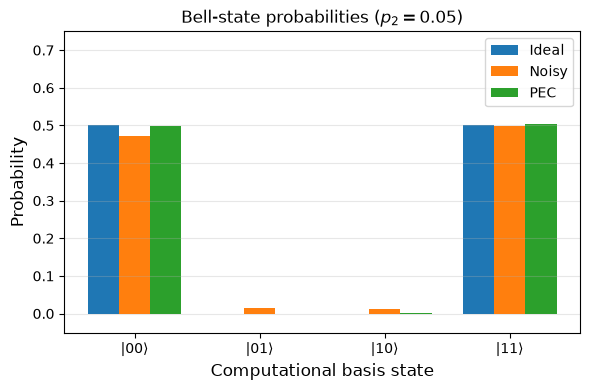

In [62]:
# Example: noisy Bell-state preparation with depolarizing noise level p2 = 0.05

zz_ideal = 1.0
p2 = 0.05
Ns_noisy = 2048

_, _, gamma2, _, _ = pec_decomposition_depolarizing(p2, 2)

Ns_per_sample = 1
Ns_pec = pec_num_samples(Ns_noisy, gamma2, n_per_sample=Ns_per_sample)

print()
print(f"Depolarizing noise level p2 = {p2}")
print(f"gamma_2^2    = {gamma2**2:.4f}")
print(f"Number of noisy shots = {Ns_noisy}")
print(f"Number of PEC samples = {Ns_pec}")
print(f"Number of shots per PEC sample = {Ns_per_sample}")
print()

zz_pec, zz_pec_std, pec_probs = pec_estimate_cnot(
    p2, num_samples=Ns_pec, num_shots_per_sample=Ns_per_sample, seed=302, return_probabilities=True
)
zz_pec_std_check = np.sqrt((gamma2**2 - zz_ideal**2) / Ns_pec)

zz_noisy, noisy_probs = noisy_bell_zz(p2, shots=Ns_noisy, seed=301, return_probabilities=True)
zz_noisy_std = np.sqrt((1 - zz_noisy**2) / Ns_noisy)

bitstrings = ["00", "01", "10", "11"]
ideal_probs = np.array([0.5, 0.0, 0.0, 0.5])

print()
print(f"ideal <ZZ>    = {zz_ideal:.4f}")
print(f"noisy <ZZ>    = {zz_noisy:.4f} ± {zz_noisy_std:.4f} ({Ns_noisy} shots)")
print(f"PEC   <ZZ>_em = {zz_pec:.4f} ± {zz_pec_std:.4f} ({Ns_pec} samples with {Ns_per_sample} shot(s) each)")
print()
print("Outcome probabilities P(00), P(01), P(10), P(11):")
print(f"ideal = {np.array2string(ideal_probs, precision=4)}")
print(f"noisy = {np.array2string(noisy_probs, precision=4)}")
print(f"PEC   = {np.array2string(pec_probs, precision=4)}")

x = np.arange(len(bitstrings))
width = 0.25
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(x - width, ideal_probs, width, label="Ideal")
ax.bar(x, noisy_probs, width, label="Noisy")
ax.bar(x + width, pec_probs, width, label="PEC")
ax.set_xticks(x)
ax.set_xticklabels([rf"$|{b}\rangle$" for b in bitstrings])
ymin = min(0.0, float(np.min(pec_probs)))
ax.set_ylim(ymin - 0.05, 0.75)
ax.set_xlabel("Computational basis state", fontsize=12)
ax.set_ylabel("Probability", fontsize=12)
ax.set_title(fr"Bell-state probabilities ($p_2={p2}$)", fontsize=12)
ax.grid(axis="y", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

#### CNOT PEC convergence

PEC is unbiased only in the infinite-sample limit. Repeat the estimate for several values of $N_s$ at $p_2 = 0.05$ and compare with the ideal and noisy values.

Loop over numbers of shots: 100%|██████████| 7/7 [51:12<00:00, 438.88s/it]


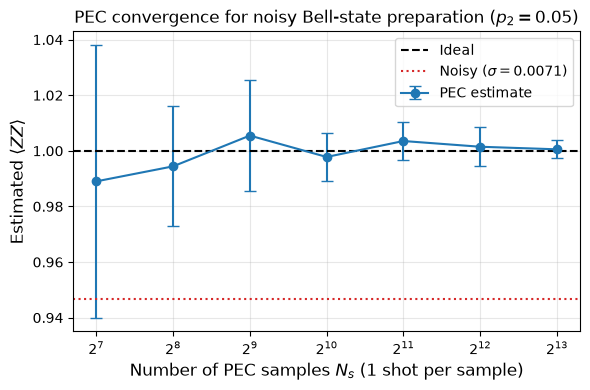

In [56]:
n_qubits = 2
p2_conv = 0.05
Ns_noisy = 2048
shots_grid = [2**7, 2**8, 2**9, 2**10, 2**11, 2**12, 2**13]
replicates = 16

bell_mean, bell_std = [], []
for n_shots in tqdm(shots_grid, desc="Loop over numbers of shots", colour="green"):
    _, _, gamma2, _, _ = pec_decomposition_depolarizing(p2_conv, n_qubits)
    Ns_pec = n_shots
    reps = [pec_estimate_cnot(p2_conv, num_samples=Ns_pec, seed=1000+37*rep+n_shots, quiet=True)[0] for rep in range(replicates)]
    bell_mean.append(float(np.mean(reps)))
    bell_std.append(float(np.std(reps)))

ideal_zz = 1.0
noisy_zz = (1 - 16 * p2_conv / 15) * ideal_zz
noisy_zz_std = np.sqrt((1 - noisy_zz**2) / Ns_noisy)

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(shots_grid, bell_mean, yerr=bell_std, marker="o", capsize=4, label="PEC estimate")
ax.axhline(ideal_zz, color="black", linestyle="--", label="Ideal")
ax.axhline(noisy_zz, color="tab:red", linestyle=":", label=fr"Noisy ($\sigma = {noisy_zz_std:.4f}$)")
ax.set_xscale("log", base=2)
ax.set_xlabel(r"Number of PEC samples $N_s$ (1 shot per sample)", fontsize=12)
ax.set_ylabel(r"Estimated $\langle ZZ \rangle$", fontsize=12)
ax.set_title(fr"PEC convergence for noisy Bell-state preparation ($p_2={p2_conv}$)", fontsize=12)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("bell_state_pec_convergence.png", dpi=300)
plt.show()

## Save results to Google Drive

In [ ]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    import shutil, os, json
    out_dir = '/content/drive/MyDrive/QFlux_VII/'
    os.makedirs(out_dir, exist_ok=True)

    shutil.copy('bell_state_pec_convergence.png', out_dir)
    with open(os.path.join(out_dir, 'ry_table.json'), 'w') as f:
        json.dump(ry_rows, f, indent=2, default=float)
    with open(os.path.join(out_dir, 'bell_curve.json'), 'w') as f:
        json.dump({'shots_grid': shots_grid, 'pec_mean': bell_mean, 'pec_std': bell_std,
                   'noisy_zz': noisy_zz, 'gamma2_sq': gamma2**2}, f, indent=2, default=float)

    print(f"\nSaved figure + data to Google Drive: {out_dir}")